# 04. Vortex profile and finite-sample spectrum

Implement the thesis vortex ansatz with a correct phase winding, then diagonalize a finite open sample. This is a thesis-based extension of the commented vortex prototype.

**Read this notebook from top to bottom.** Each section explains one calculation before showing its code. All functions needed to run it are visible below; no earlier notebook is required.

**Source labels.** **Thesis** identifies the stated model in Aditya Banerjee's [2023 MSc thesis](https://drive.google.com/file/d/1d9WheYwEY23cPAlLxxVOUfQDr9jLdqb9/view). **Source translation** identifies the active Mathematica calculation at commit `d88d12c`. **Extension / algebra** identifies new Python implementation or explicit derivations. Numerical output is evidence only for the displayed parameters. No speculative physical identification is assumed.

**Units and conventions.** Choose one energy unit $E_0$ and lattice spacing $a$. Displayed energies mean $E/E_0$, coordinates mean $x/a$, and $k_x,k_y$ mean momentum times $a$. Thus $m,\lambda,\mu,\Delta,V,k_BT$ all have energy units before rescaling. Eigenvectors have norm one and dimensionless components. This is a nonrelativistic lattice calculation; no spacetime metric signature is used. Boundary conditions and the spin/Nambu basis are stated where each matrix is built.

**Code provenance.** The original files are [BdG topological.nb](https://github.com/adicos0/BdG-code-for-Topological-superconductor-with-vortex-/blob/d88d12cded1a954d53c2d36d515525c8100ded1c/BdG%20topological.nb) and [added vortex.nb](https://github.com/adicos0/BdG-code-for-Topological-superconductor-with-vortex-/blob/d88d12cded1a954d53c2d36d515525c8100ded1c/added%20vortex.nb). See [SOURCE_MAP.md](../SOURCE_MAP.md) for exact cells, differences and references. Python functions are also collected in `python/bdg_models.py` for testing; the definitions here are identical.

## 1. Imports

In [1]:
import os
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("OMP_NUM_THREADS", "1")
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import eigh
from scipy.special import expit
plt.rcParams.update({"figure.figsize": (7, 4), "font.size": 11})

## 2. Define the vortex before inserting numbers

**Thesis:** §4.2, Eq. (4.2), uses
$$\Delta(x,y)=\Delta_0\tanh(r/\xi)e^{iq\phi},\qquad
r=\sqrt{(x-x_0)^2+(y-y_0)^2}.$$
Here $\Delta_0$ is the far-field pairing energy, $(x_0,y_0)$ is the vortex centre, $\xi>0$ is the recovery length, and $q=1$ describes one positive winding. $r/\xi$ and $q\phi$ are dimensionless.

**Explicit correction to thesis Eq. (4.4) and commented code:** use
$$\phi=\operatorname{atan2}(y-y_0,x-x_0).$$
The printed/source expression $\arctan(|y-y_0|/|x-x_0|)$ loses quadrant information and cannot describe a full $2\pi$ winding. The corrected phase is essential, not a cosmetic plotting change. At $r=0$, phase is undefined but $\Delta=0$, so its assigned numerical value has no physical effect.

**Limits:** since $\tanh z=z+O(z^3)$, near the centre $|\Delta|\simeq\Delta_0r/\xi$. As $r/\xi\to\infty$, $|\Delta|\to\Delta_0$. A closed loop around the centre has phase increment $2\pi q$.

**Length convention:** thesis Eq. (4.3) writes a coherence-length relation involving a penetration length and gap, but without a specified unit conversion it cannot be used as an SI length formula. Here $\xi/a$ is an independently chosen dimensionless input, not a material prediction.

**Boundary assumption:** use open boundaries for this isolated imposed vortex. No vector potential, magnetic screening, flux quantization calculation, or self-consistent relaxation is included. A periodic vortex lattice needs additional gauge construction; see [Pathak, Plugge & Franz, §2.2](https://arxiv.org/html/2012.10588v2).

In [2]:
def coordinates(nx, ny):
    """Zero-based version of the source's x-outer, y-inner site order."""
    return np.array([(x, y) for x in range(nx) for y in range(ny)])

def thesis_normal(nx, ny, m=0.5, lam=1.0, mu=0.0, periodic=False):
    """Extension from thesis Eqs. 4.8-4.9, not the active source hopping.

    Fourier convention c_r = sum_k exp(-i k.r)c_k / sqrt(N).
    Build site-major 2x2 blocks, then permute to spin-major order.
    """
    identity = np.eye(2)
    sx = np.array([[0, 1], [1, 0]], complex)
    sy = np.array([[0, -1j], [1j, 0]], complex)
    sz = np.diag([1., -1.])
    n = nx*ny
    h = np.kron(np.eye(n), 1.5*m*sz-mu*identity).astype(complex)
    for i, (x, y) in enumerate(coordinates(nx, ny)):
        for dx, dy, spin in [(1, 0, sx), (0, 1, sy)]:
            for distance, hop in [(1, -m/2*sz + 0.5j*lam*spin),
                                  (2, m/8*sz)]:
                xx, yy = x+distance*dx, y+distance*dy
                if not periodic and not (0 <= xx < nx and 0 <= yy < ny):
                    continue
                j = (xx % nx)*ny + (yy % ny)
                h[2*i:2*i+2, 2*j:2*j+2] += hop
                h[2*j:2*j+2, 2*i:2*i+2] += hop.conj().T
    order = np.r_[np.arange(0, 2*n, 2), np.arange(1, 2*n, 2)]
    return h[np.ix_(order, order)]

def canonical_bdg(electron, delta):
    """Standard spin-singlet BdG in (c_up,c_down,c_up†,c_down†)."""
    n = len(delta)
    zero = np.zeros((n, n), complex)
    pairing = np.block([[zero, np.diag(delta)], [-np.diag(delta), zero]])
    return np.block([[electron, pairing],
                     [pairing.conj().T, -electron.conj()]])

def canonical_checks(matrix):
    """Hermiticity and particle-hole residuals (max absolute entries)."""
    half = len(matrix)//2
    exchange = np.r_[np.arange(half, 2*half), np.arange(half)]
    return (np.max(abs(matrix-matrix.conj().T)),
            np.max(abs(matrix.conj()[np.ix_(exchange, exchange)]+matrix)))

def vortex_field(nx, ny, delta0=0.2, xi=1.5, center=None, winding=1):
    """Imposed open-sample extension of Eq.4.2 with quadrant-correct phase."""
    if xi <= 0:
        raise ValueError('xi must be positive.')
    if center is None:
        center = ((nx-1)/2, (ny-1)/2)
    xy = coordinates(nx, ny)-np.asarray(center)
    radius = np.hypot(xy[:, 0], xy[:, 1])
    phase = np.arctan2(xy[:, 1], xy[:, 0])
    return delta0*np.tanh(radius/xi)*np.exp(1j*winding*phase)

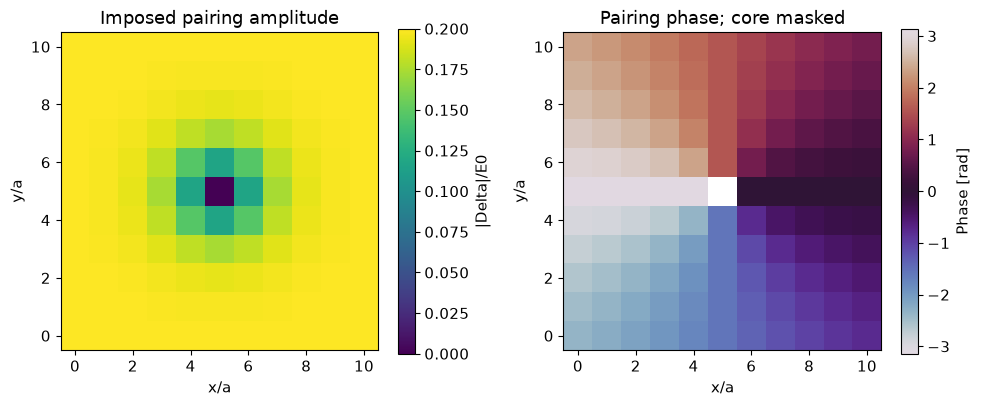

In [3]:
# Illustrative finite-size parameters, NOT a thesis figure reproduction.
# m and lambda follow the original scale; delta0 and xi are tutorial inputs.
nx = ny = 11
n = nx*ny
center = (5, 5)
delta0, xi, mu = 0.2, 1.5, -0.7
delta = vortex_field(nx, ny, delta0, xi, center)
xy = coordinates(nx, ny)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, values, cmap, limits, title in [
    (axes[0], abs(delta), "viridis", (0, delta0), "Imposed pairing amplitude"),
    (axes[1], np.ma.masked_where(abs(delta)<1e-12, np.angle(delta)), "twilight", (-np.pi, np.pi), "Pairing phase; core masked")]:
    plot = ax.imshow(values.reshape(nx, ny).T, origin="lower", interpolation="nearest",
                     cmap=cmap, vmin=limits[0], vmax=limits[1])
    ax.set(xlabel="x/a", ylabel="y/a", title=title)
    fig.colorbar(plot, ax=ax, label="|Delta|/E0" if ax is axes[0] else "Phase [rad]")
fig.tight_layout()
plt.show()

## 3. Check the winding and amplitude limits

Take a counterclockwise square loop around the core, without passing through it. For consecutive complex gap values $\Delta_j$, the phase increment is $\arg(\Delta_{j+1}\Delta_j^*)$. Sum these increments and divide by $2\pi$:
$$q_{\rm measured}=\frac{1}{2\pi}\sum_j\arg(\Delta_{j+1}\Delta_j^*).$$
The loop must be sampled finely enough that each true phase step is smaller than $\pi$; the loop below satisfies this. We also compare the core and far-corner amplitudes with the stated ansatz.

In [4]:
loop_xy = ([(x, 2) for x in range(2, 8)] + [(8, y) for y in range(2, 8)]
           + [(x, 8) for x in range(8, 2, -1)] + [(2, y) for y in range(8, 2, -1)])
loop = np.array([delta[x*ny+y] for x, y in loop_xy])
winding = np.angle(np.roll(loop, -1)*loop.conj()).sum()/(2*np.pi)
core = center[0]*ny+center[1]
print("Measured counterclockwise winding:", winding)
print("Core amplitude/E0:", abs(delta[core]))
print("Corner amplitude / delta0:", abs(delta[0])/delta0)
assert np.isclose(winding, 1)
assert abs(delta[core]) < 1e-12

Measured counterclockwise winding: 1.0
Core amplitude/E0: 0.0
Corner amplitude / delta0: 0.999839147645202


## 4. Diagonalize the imposed-vortex Hamiltonian

**Extension:** use the thesis normal-state Hamiltonian from notebook 01, the canonical spin-singlet BdG matrix from notebook 02, and the imposed profile above. The pairing is held fixed. We compare against the same open sample with uniform $\Delta_0$, so the only changed input in this comparison is the gap profile.

For a state $w_n$, the total Nambu probability at site $i$ is
$$p_{i,n}=|u_{i\uparrow,n}|^2+|u_{i\downarrow,n}|^2+|v_{i\uparrow,n}|^2+|v_{i\downarrow,n}|^2.$$
Its site sum is one. We average over the four states closest to zero energy; this makes the plot insensitive to rotations within a fully included degenerate subspace. It is a probability map, **not LDOS**. The selected group must not cut through a degeneracy; we report the separation to the next state.

Hermiticity / particle-hole residuals: (np.float64(0.0), np.float64(0.0))
Selected energies/E0: [ 0.00061295 -0.00061295  0.01510573 -0.01510573]
Separation from next |E| / E0: 0.010760050170815383
Spatial probability sum: 0.9999999999999998
Mean selected-state weight on outermost boundary: 0.7797541621515373
Mean selected-state weight within radius 2a of core: 0.03772185349140905


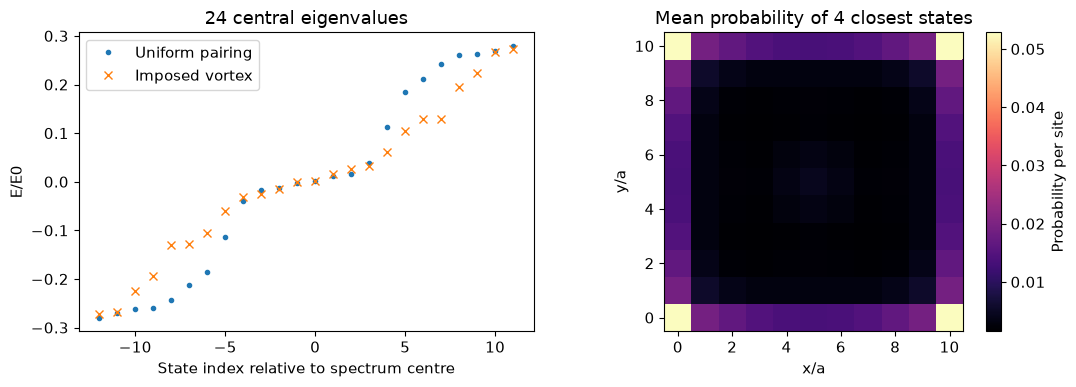

In [5]:
electron = thesis_normal(nx, ny, mu=mu, periodic=False)
h_vortex = canonical_bdg(electron, delta)
h_uniform = canonical_bdg(electron, np.full(n, delta0))
energies, vectors = eigh(h_vortex)
uniform_energies = eigh(h_uniform, eigvals_only=True)
print("Hermiticity / particle-hole residuals:", canonical_checks(h_vortex))
order = np.argsort(abs(energies))
selected = order[:4]
separation = abs(energies[order[4]])-abs(energies[order[3]])
print("Selected energies/E0:", energies[selected])
print("Separation from next |E| / E0:", separation)
probability = (abs(vectors[:, selected])**2).reshape(4, n, 4).sum(axis=0).mean(axis=1)
print("Spatial probability sum:", probability.sum())
boundary = (xy[:, 0] == 0) | (xy[:, 0] == nx-1) | (xy[:, 1] == 0) | (xy[:, 1] == ny-1)
core_region = np.linalg.norm(xy-np.array(center), axis=1) <= 2
print("Mean selected-state weight on outermost boundary:", probability[boundary].sum())
print("Mean selected-state weight within radius 2a of core:", probability[core_region].sum())
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for spectrum, label, marker in [(uniform_energies, "Uniform pairing", "."), (energies, "Imposed vortex", "x")]:
    middle = spectrum[len(spectrum)//2-12:len(spectrum)//2+12]
    axes[0].plot(np.arange(-12, 12), middle, marker, label=label)
axes[0].set(xlabel="State index relative to spectrum centre", ylabel="E/E0", title="24 central eigenvalues")
axes[0].legend()
plot = axes[1].imshow(probability.reshape(nx, ny).T, origin="lower", interpolation="nearest", cmap="magma")
axes[1].set(xlabel="x/a", ylabel="y/a", title="Mean probability of 4 closest states")
fig.colorbar(plot, ax=axes[1], label="Probability per site")
fig.tight_layout()
plt.show()

## 5. Interpretation and limits

**Computed facts:** the output gives finite-sample energies, winding and spatial weights for an imposed profile. With the displayed parameters, the selected four-state average has most of its weight near the outer boundary, rather than the core. The printed boundary and core-region weights quantify this observation; they are not a topological classification. **Not established here:** self-consistency of the vortex, a thermodynamic gap, or a Majorana zero mode. A small eigenvalue alone does not settle these questions. The thesis discusses such interpretations, while these notebooks keep the calculation and identification separate. [Fu & Kane (2008)](https://arxiv.org/abs/0707.1692) provides the underlying theoretical context for induced superconductivity and vortices on a topological-insulator surface.